## 1. Recolección y comprensión de los datos

### 1.1 Carga del dataset original
Se carga el archivo original `Mall_Customers.xlsx`, que corresponde al mismo conjunto de datos utilizado en
la Semana 3 (encuestas voluntarias y tarjetas de fidelización del centro comercial). El archivo original se
mantiene sin modificaciones en `data/raw`; todas las transformaciones se realizan sobre una copia.

In [1]:
import pandas as pd
import numpy as np
from google.colab import drive
drive.mount('/content/drive')

RUTA_RAW = '/content/drive/MyDrive/GDT2202_S6/Data/Raw/Mall Customers.xlsx'
df_raw = pd.read_excel(RUTA_RAW)
df = df_raw.copy()          # trabajaremos sobre la copia

print("Registros y variables:", df_raw.shape)
print(df_raw.dtypes)
df_raw.head()

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Registros y variables: (200, 7)
CustomerID                 int64
Gender                    object
Age                        int64
Education                 object
Marital Status            object
Annual Income (k$)         int64
Spending Score (1-100)     int64
dtype: object


,CustomerID,Gender,Age,Education,Marital Status,Annual Income (k$),Spending Score (1-100)
0,1,M,19,High School,Married,15,39
1,2,M,21,Graduate,Single,15,81
2,3,F,20,Graduate,Married,16,6
3,4,F,23,High School,Unknown,16,77
4,5,F,31,Uneducated,Married,17,40


### 1.2 Estructura general del dataset
Se revisa la dimensión, los tipos de datos y los nombres exactos de las columnas del archivo original, como
punto de partida del diagnóstico de calidad (sección 2.1).

In [2]:
print("Dimensión:", df_raw.shape)
print("\nNombres exactos de las columnas (repr muestra espacios ocultos):")
print([repr(c) for c in df_raw.columns])
print()
df_raw.info()

Dimensión: (200, 7)

Nombres exactos de las columnas (repr muestra espacios ocultos):
["'CustomerID'", "'Gender'", "'Age'", "'Education '", "'Marital Status'", "'Annual Income (k$)'", "'Spending Score (1-100)'"]

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 7 columns):
 #   Column                  Non-Null Count  Dtype 
---  ------                  --------------  ----- 
 0   CustomerID              200 non-null    int64 
 1   Gender                  200 non-null    object
 2   Age                     200 non-null    int64 
 3   Education               200 non-null    object
 4   Marital Status          200 non-null    object
 5   Annual Income (k$)      200 non-null    int64 
 6   Spending Score (1-100)  200 non-null    int64 
dtypes: int64(4), object(3)
memory usage: 11.1+ KB


### 1.3 Exploración de categorías y rangos
Se revisan los valores únicos de las variables categóricas y el resumen estadístico de las numéricas, para
documentar el diccionario de datos y detectar valores atípicos o codificaciones especiales.

In [3]:
for col in ['Gender', 'Education ', 'Marital Status']:
    print(f"--- {col!r} ---")
    print(df_raw[col].value_counts(dropna=False))
    print()

df_raw.describe().round(2)

--- 'Gender' ---
Gender
F    112
M     88
Name: count, dtype: int64

--- 'Education ' ---
Education 
Graduate         67
High School      40
Uneducated       31
Unknown          26
College          17
Doctorate        11
Post-Graduate     8
Name: count, dtype: int64

--- 'Marital Status' ---
Marital Status
Married     112
Single       61
Unknown      15
Divorced     12
Name: count, dtype: int64



,CustomerID,Age,Annual Income (k$),Spending Score (1-100)
count,200.00,200.00,200.00,200.00
mean,100.50,38.85,60.56,50.20
std,57.88,13.97,26.26,25.82
min,1.00,18.00,15.00,1.00
25%,50.75,28.75,41.50,34.75
50%,100.50,36.00,61.50,50.00
75%,150.25,49.00,78.00,73.00
max,200.00,70.00,137.00,99.00


### 1.4 Verificación del identificador
Antes de excluir `CustomerID` del análisis, se verifica que sea único, para confirmar que no hay registros
duplicados y que puede descartarse sin perder trazabilidad.

In [4]:
print("IDs únicos:", df_raw['CustomerID'].nunique(), "de", len(df_raw))
print("IDs duplicados:", df_raw['CustomerID'].duplicated().sum())
print("Filas completamente duplicadas (sin ID):",
      df_raw.drop(columns='CustomerID').duplicated().sum())

IDs únicos: 200 de 200
IDs duplicados: 0
Filas completamente duplicadas (sin ID): 0


### 1.5 Diccionario de datos
Se documenta cada variable: significado, tipo, valores posibles y observaciones de calidad detectadas en la
exploración inicial. El diccionario se guarda en `docs/diccionario_datos.csv`.

In [5]:
diccionario = pd.DataFrame([
    ['CustomerID', 'Identificador', 'Entero 1-200', 'Identificador correlativo del cliente. Se excluye del análisis (privacidad).'],
    ['Gender', 'Categórica nominal', 'F, M', 'Género del cliente.'],
    ['Age', 'Numérica discreta', '18-70 años', 'Edad en años.'],
    ['Education', 'Categórica ordinal (orden asumido)', 'Uneducated, High School, College, Graduate, Post-Graduate, Doctorate, Unknown', 'Nivel educacional. Contiene 26 Unknown (13 %).'],
    ['Marital Status', 'Categórica nominal', 'Married, Single, Divorced, Unknown', 'Estado civil. Contiene 15 Unknown (7,5 %).'],
    ['Annual Income (k$)', 'Numérica', '15-137 miles de USD', 'Ingreso anual. Posible outlier en el máximo (137).'],
    ['Spending Score (1-100)', 'Numérica', '1-99', 'Puntaje de gasto asignado por el centro comercial.'],
], columns=['variable', 'tipo', 'valores_posibles', 'descripcion_y_observaciones'])

diccionario

,variable,tipo,valores_posibles,descripcion_y_observaciones
0,CustomerID,Identificador,Entero 1-200,Identificador correlativo del cliente. Se excl...
1,Gender,Categórica nominal,"F, M",Género del cliente.
2,Age,Numérica discreta,18-70 años,Edad en años.
3,Education,Categórica ordinal (orden asumido),"Uneducated, High School, College, Graduate, Po...",Nivel educacional. Contiene 26 Unknown (13 %).
4,Marital Status,Categórica nominal,"Married, Single, Divorced, Unknown","Estado civil. Contiene 15 Unknown (7,5 %)."
5,Annual Income (k$),Numérica,15-137 miles de USD,Ingreso anual. Posible outlier en el máximo (1...
6,Spending Score (1-100),Numérica,1-99,Puntaje de gasto asignado por el centro comerc...


## 2. Limpieza y transformación de datos

### 2.1 Diagnóstico de calidad: valores atípicos en ingreso anual
El resumen estadístico mostró un ingreso máximo de 137 usd, muy por encima del percentil 75 (78 k$). Para
evaluar si es un valor atípico se aplica la regla del rango intercuartílico (IQR): se considera atípico
todo valor mayor que Q3 + 1,5 × IQR.

In [6]:
q1 = df_raw['Annual Income (k$)'].quantile(0.25)
q3 = df_raw['Annual Income (k$)'].quantile(0.75)
iqr = q3 - q1
lim_sup = q3 + 1.5 * iqr
print(q1, q3, iqr, lim_sup)

41.5 78.0 36.5 132.75


#### Registros fuera del límite superior
Se identifican los registros cuyo ingreso supera el límite del IQR (132,75 miles de USD) para evaluarlos
individualmente antes de decidir si se conservan, se corrigen o se eliminan.

In [7]:
atipicos = df_raw[df_raw['Annual Income (k$)'] > lim_sup]
print("Registros sobre el límite:", len(atipicos))
atipicos

Registros sobre el límite: 2


,CustomerID,Gender,Age,Education,Marital Status,Annual Income (k$),Spending Score (1-100)
198,199,M,32,High School,Married,137,18
199,200,M,30,College,Married,137,83


### 2.2 Valores faltantes codificados como "Unknown"
Education y Marital Status no presentan nulos formales, pero contienen la categoría `Unknown`, que
representa información no disponible. Se cuantifica su magnitud y si coinciden en los mismos registros.

In [8]:
unk_edu = df_raw['Education '] == 'Unknown'
unk_mar = df_raw['Marital Status'] == 'Unknown'

print("Unknown en Education:", unk_edu.sum())
print("Unknown en Marital Status:", unk_mar.sum())
print("En ambas a la vez:", (unk_edu & unk_mar).sum())
print("Registros con al menos un Unknown:", (unk_edu | unk_mar).sum(),
      f"({(unk_edu | unk_mar).mean():.1%})")

Unknown en Education: 26
Unknown en Marital Status: 15
En ambas a la vez: 2
Registros con al menos un Unknown: 39 (19.5%)


### 2.3 Aplicación de la limpieza y transformación
Sobre una copia del dataset original se aplican las decisiones tomadas en el diagnóstico:
1. Corregir el nombre de columna `Education ` (espacio final) y estandarizar los nombres.
2. Eliminar espacios en blanco en los valores de texto.
3. Excluir `CustomerID` del conjunto procesado (privacidad; unicidad ya verificada).
4. Convertir las variables de texto a tipo categórico.
5. Conservar `Unknown` como categoría propia y mantener los dos atípicos de ingreso (IDs 199 y 200).

In [9]:
df = df_raw.copy()

# 1. Nombres de columnas: quitar espacios sobrantes
df.columns = df.columns.str.strip()

# 2. Valores de texto: quitar espacios al inicio y final
for col in ['Gender', 'Education', 'Marital Status']:
    df[col] = df[col].str.strip()

# 3. Excluir el identificador
df = df.drop(columns='CustomerID')

# 4. Tipos categóricos
orden_edu = ['Uneducated', 'High School', 'College', 'Graduate', 'Post-Graduate', 'Doctorate']
df['Gender'] = df['Gender'].astype('category')
df['Marital Status'] = df['Marital Status'].astype('category')
df['Education'] = pd.Categorical(df['Education'], categories=orden_edu + ['Unknown'])

print(df.shape)
df.info()

(200, 6)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 6 columns):
 #   Column                  Non-Null Count  Dtype   
---  ------                  --------------  -----   
 0   Gender                  200 non-null    category
 1   Age                     200 non-null    int64   
 2   Education               200 non-null    category
 3   Marital Status          200 non-null    category
 4   Annual Income (k$)      200 non-null    int64   
 5   Spending Score (1-100)  200 non-null    int64   
dtypes: category(3), int64(3)
memory usage: 6.1 KB


### 2.4 Evidencia antes y después de la limpieza
Se comparan indicadores de calidad del dataset original (`df_raw`) y del dataset procesado (`df`) para
documentar el efecto de cada transformación.

In [10]:
antes_despues = pd.DataFrame({
    'Indicador': [
        'Registros', 'Columnas', 'Nombres de columna con espacios',
        'Nulos formales', 'Registros con Unknown', 'Duplicados',
        'Atípicos de ingreso (IQR)', 'Variables categóricas como object',
        'Memoria (KB)'
    ],
    'Antes (df_raw)': [
        len(df_raw), df_raw.shape[1],
        sum(c != c.strip() for c in df_raw.columns),
        int(df_raw.isna().sum().sum()),
        int(((df_raw['Education '] == 'Unknown') | (df_raw['Marital Status'] == 'Unknown')).sum()),
        int(df_raw.duplicated().sum()),
        int((df_raw['Annual Income (k$)'] > lim_sup).sum()),
        int((df_raw.dtypes == 'object').sum()),
        round(df_raw.memory_usage(deep=True).sum() / 1024, 1)
    ],
    'Después (df)': [
        len(df), df.shape[1],
        sum(c != c.strip() for c in df.columns),
        int(df.isna().sum().sum()),
        int(((df['Education'] == 'Unknown') | (df['Marital Status'] == 'Unknown')).sum()),
        int(df.duplicated().sum()),
        int((df['Annual Income (k$)'] > lim_sup).sum()),
        int((df.dtypes == 'object').sum()),
        round(df.memory_usage(deep=True).sum() / 1024, 1)
    ]
})
antes_despues

,Indicador,Antes (df_raw),Después (df)
0,Registros,200.0,200.0
1,Columnas,7.0,6.0
2,Nombres de columna con espacios,1.0,0.0
3,Nulos formales,0.0,0.0
4,Registros con Unknown,39.0,39.0
5,Duplicados,0.0,0.0
6,Atípicos de ingreso (IQR),2.0,2.0
7,Variables categóricas como object,3.0,0.0
8,Memoria (KB),38.4,6.7


### 2.5 Validaciones finales y guardado del dataset procesado
Se verifican reglas de consistencia sobre el dataset procesado y se guarda el resultado en
`data/processed`, junto con el registro de validaciones en `docs/log_validaciones.csv`.

In [11]:
validaciones = pd.DataFrame([
    ['Edad entre 18 y 100',            df['Age'].between(18, 100).all()],
    ['Ingreso mayor a 0',              (df['Annual Income (k$)'] > 0).all()],
    ['Spending Score entre 1 y 100',   df['Spending Score (1-100)'].between(1, 100).all()],
    ['Sin nulos',                      df.isna().sum().sum() == 0],
    ['Sin duplicados',                 df.duplicated().sum() == 0],
    ['Gender solo F/M',                set(df['Gender'].unique()) <= {'F', 'M'}],
    ['Sin columna identificadora',     'CustomerID' not in df.columns],
], columns=['regla', 'cumple'])
validaciones['cumple'] = validaciones['cumple'].map({True: 'Sí', False: 'No'})
print(validaciones)

BASE = '/content/drive/MyDrive/GDT2202_S6'
df.to_csv(f'{BASE}/Data/Processed/Mall_customers_limpio.csv', index=False)
validaciones.to_csv(f'{BASE}/Docs/log_validaciones.csv', index=False)
diccionario.to_csv(f'{BASE}/Docs/diccionario_datos.csv', index=False)

                          regla cumple
0           Edad entre 18 y 100     Sí
1             Ingreso mayor a 0     Sí
2  Spending Score entre 1 y 100     Sí
3                     Sin nulos     Sí
4                Sin duplicados     Sí
5               Gender solo F/M     Sí
6    Sin columna identificadora     Sí


## 3. Análisis exploratorio de datos (EDA)

### 3.1 Exploración inicial
Se examinan las distribuciones de las variables numéricas, las relaciones entre ellas y las diferencias del
puntaje de gasto según las variables categóricas, con el fin de identificar hallazgos relevantes.

In [12]:
print("Correlaciones entre variables numéricas:")
print(df[['Age', 'Annual Income (k$)', 'Spending Score (1-100)']].corr().round(2))

for col in ['Gender', 'Education', 'Marital Status']:
    print(f"\nSpending Score según {col}:")
    print(df.groupby(col, observed=True)['Spending Score (1-100)']
            .agg(['count', 'mean', 'median']).round(1))

Correlaciones entre variables numéricas:
                         Age  Annual Income (k$)  Spending Score (1-100)
Age                     1.00               -0.01                   -0.33
Annual Income (k$)     -0.01                1.00                    0.01
Spending Score (1-100) -0.33                0.01                    1.00

Spending Score según Gender:
        count  mean  median
Gender                     
F         112  51.5    50.0
M          88  48.5    50.0

Spending Score según Education:
               count  mean  median
Education                         
Uneducated        31  46.8    46.0
High School       40  47.8    51.5
College           17  48.2    42.0
Graduate          67  51.6    51.0
Post-Graduate      8  47.9    46.0
Doctorate         11  51.5    47.0
Unknown           26  55.7    54.5

Spending Score según Marital Status:
                count  mean  median
Marital Status                     
Divorced           12  52.6    52.0
Married           112  49.7    

### 3.1 Hallazgos del análisis exploratorio

**Hallazgo 1: no existe relación lineal entre el ingreso anual y el puntaje de gasto.**
El coeficiente de correlación es 0,01, es decir, nulo. Sin embargo, el gráfico de dispersión (Visualización 1) muestra agrupaciones de clientes, por lo que la ausencia de relación lineal no implica ausencia de estructura.

**Hallazgo 2: la edad presenta una correlación negativa moderada con el puntaje de gasto.**
La correlación es de −0,33: a mayor edad tiende a observarse un menor puntaje de gasto. La edad explica solo cerca del 11 % de la variación del gasto, por lo que es un factor asociado pero no determinante, y se trata de una asociación, no de una relación causal.

**Hallazgo 3: la categoría `Unknown` presenta el puntaje de gasto promedio más alto.**
En educación, `Unknown` alcanza un promedio de 55,7 (n = 26) frente a 46,8–51,6 en el resto de las categorías, y en estado civil 54,3 (n = 15) frente a 49,7–52,6. Las diferencias son de pocos puntos y los grupos son pequeños, por lo que se considera un dato a vigilar y no una conclusión. Esto justifica haber conservado `Unknown` como categoría propia en lugar de imputarla.

### 3.2 Visualización 1: ingreso anual vs puntaje de gasto
**Objetivo:** el coeficiente de correlación entre ingreso y puntaje de gasto es cercano a cero (r = 0,01), lo
que descarta una relación lineal. Se utiliza un gráfico de dispersión para verificar si existe algún otro
patrón (por ejemplo, grupos de clientes) que el coeficiente no detecta.

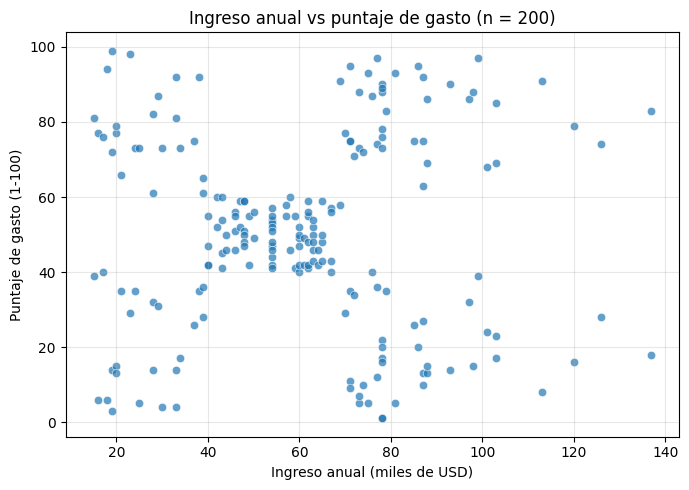

In [13]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(7, 5))
ax.scatter(df['Annual Income (k$)'], df['Spending Score (1-100)'],
           alpha=0.7, edgecolor='white', linewidth=0.5)
ax.set_xlabel('Ingreso anual (miles de USD)')
ax.set_ylabel('Puntaje de gasto (1-100)')
ax.set_title('Ingreso anual vs puntaje de gasto (n = 200)')
ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig('/content/drive/MyDrive/GDT2202_S6/Figuras/fig1_ingreso_vs_gasto.png', dpi=150)
plt.show()

**Interpretación:** el gráfico muestra que, aunque la correlación lineal entre ingreso anual y puntaje de gasto es prácticamente nula (r = 0,01), los clientes no se distribuyen al azar. Se observa un bloque denso en el centro (ingresos medios y puntajes de gasto medios) y agrupaciones más dispersas hacia las cuatro esquinas: ingreso bajo con gasto alto, ingreso bajo con gasto bajo, ingreso alto con gasto alto e ingreso alto con gasto bajo. Estas agrupaciones se compensan entre sí y explican por qué el coeficiente de correlación no detecta ninguna relación. Los dos clientes con ingreso atípico (137 miles de USD) quedan dentro de los grupos de ingreso alto, lo que respalda la decisión de conservarlos. Se trata de una observación visual que sugiere la existencia de segmentos de clientes; su confirmación requeriría un método de agrupamiento en una etapa posterior.

### 3.2 Visualización 2: edad vs puntaje de gasto
**Objetivo:** la edad presenta una correlación negativa moderada con el puntaje de gasto (r = −0,33). Se
utiliza un gráfico de dispersión con línea de tendencia para evaluar si esa relación es homogénea a lo largo
de todas las edades o si se concentra en algún tramo etario.

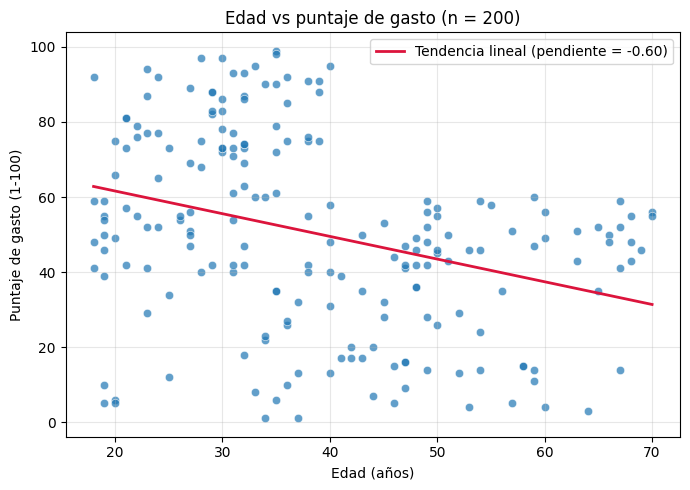

In [15]:
x = df['Age']
y = df['Spending Score (1-100)']
pendiente, intercepto = np.polyfit(x, y, 1)

fig, ax = plt.subplots(figsize=(7, 5))
ax.scatter(x, y, alpha=0.7, edgecolor='white', linewidth=0.5)
xs = np.linspace(x.min(), x.max(), 100)
ax.plot(xs, pendiente * xs + intercepto, color='crimson', linewidth=2,
        label=f'Tendencia lineal (pendiente = {pendiente:.2f})')
ax.set_xlabel('Edad (años)')
ax.set_ylabel('Puntaje de gasto (1-100)')
ax.set_title('Edad vs puntaje de gasto (n = 200)')
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig('/content/drive/MyDrive/GDT2202_S6/Figuras/fig2_edad_vs_gasto.png', dpi=150)
plt.show()

**Interpretación:** la línea de tendencia tiene una pendiente de −0,60, es decir, en promedio cada año adicional de edad se asocia con unos 0,6 puntos menos de gasto. Sin embargo, la relación no es homogénea: en clientes menores de aproximadamente 40 años los puntajes se dispersan en todo el rango (de valores muy bajos a cercanos a 100), mientras que en los mayores de esa edad casi no aparecen puntajes altos. La tendencia negativa se debe principalmente a la ausencia de gasto alto en edades mayores y no a que todos los clientes jóvenes gasten más. Además, la edad explica solo cerca del 11 % de la variación del puntaje de gasto (r² ≈ 0,11), por lo que es un factor asociado pero no suficiente por sí solo para explicar el comportamiento de compra. Cabe señalar que se trata de una asociación y no de una relación causal.